# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [15]:
import pandas as pd
import kagglehub
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [16]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("parthfr/marvel-cinematic-universe-boxoffice-csv")

print("Path to dataset files:", path)
df = pd.read_csv(os.path.join(path, "mcu.csv"))

print("Dataset loaded successfully!")

df.head()

Using Colab cache for faster access to the 'marvel-cinematic-universe-boxoffice-csv' dataset.
Path to dataset files: /kaggle/input/marvel-cinematic-universe-boxoffice-csv
Dataset loaded successfully!


,movie_title,mcu_phase,release_date,tomato_meter,audience_score,movie_duration,production_budget,opening_weekend,domestic_box_office,worldwide_box_office
0,Iron Man,Phase 1,2008-05-02,94,91,126.0,140000000.0,102118668.0,319034126.0,585796247.0
1,The Incredible Hulk,Phase 1,2008-06-13,67,70,112.0,137500000.0,55414050.0,134806913.0,265573859.0
2,Iron Man 2,Phase 1,2010-05-07,72,71,124.0,200000000.0,128122480.0,312433331.0,621156389.0
3,Thor,Phase 1,2011-05-06,77,76,114.0,150000000.0,65723338.0,181030624.0,449326618.0
4,Captain America The First Avenger,Phase 1,2011-07-22,80,75,124.0,140000000.0,65058524.0,176654505.0,370569774.0


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

Antes de rodar: o MCU BoxOffice tem 10 variáveis preditoras (tomato_meter, audience_score, movie_duration, production_budget, opening_weekend, domestic_box_office, entre outras) mais o alvo (resultado_financeiro, presença/ausência de lucro). Quantas linhas você esperam que um dataset de bilheteria como esse tenha — dezenas, centenas ou milhares de filmes?

### Dimensão e Tipos de Dados

In [17]:
df.shape

(62, 10)

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   movie_title           62 non-null     object 
 1   mcu_phase             62 non-null     object 
 2   release_date          62 non-null     object 
 3   tomato_meter          62 non-null     int64  
 4   audience_score        62 non-null     int64  
 5   movie_duration        38 non-null     float64
 6   production_budget     38 non-null     float64
 7   opening_weekend       38 non-null     float64
 8   domestic_box_office   38 non-null     float64
 9   worldwide_box_office  38 non-null     float64
dtypes: float64(5), int64(2), object(3)
memory usage: 5.0+ KB


In [19]:
df.describe()

,tomato_meter,audience_score,movie_duration,production_budget,opening_weekend,domestic_box_office,worldwide_box_office
count,62.000000,62.000000,38.000000,3.800000e+01,3.800000e+01,3.800000e+01,3.800000e+01
mean,82.629032,81.209677,130.868421,2.034605e+08,1.377335e+08,3.671251e+08,9.137550e+08
std,12.715337,14.044586,15.518378,5.559924e+07,7.728089e+07,2.054218e+08,5.823871e+08
min,46.000000,32.000000,105.000000,1.300000e+08,4.611086e+07,8.450022e+07,2.061368e+08
25%,77.000000,76.250000,118.750000,1.700000e+08,8.156431e+07,2.083978e+08,4.868814e+08
50%,86.000000,86.000000,128.500000,2.000000e+08,1.173362e+08,3.261054e+08,7.671391e+08
75%,91.750000,91.000000,136.000000,2.237500e+08,1.807896e+08,4.229553e+08,1.147956e+09
max,99.000000,98.000000,181.000000,3.650000e+08,3.600916e+08,8.584002e+08,2.799439e+09


### Duplicadas

In [20]:
df.duplicated().sum()

np.int64(0)

### Renomeando o atributo alvo para facilitar a interpretação

O dataset original registra `worldwide_box_office` em uma escala contínua (bilheteria mundial em dólares). Pra hoje, vamos simplificar para uma variável binária, presença ou ausência de lucro (comparando bilheteria vs. orçamento), já que é essa a distinção que vamos usar nas cores ao longo da aula (azul = prejuízo, vermelho = lucrativo).

In [21]:
df["resultado_financeiro"] = np.where(
    df["worldwide_box_office"] > df["production_budget"], "Lucrativo", "Prejuízo"
)
df["resultado_financeiro"].value_counts()
df.head()

,movie_title,mcu_phase,release_date,tomato_meter,audience_score,movie_duration,production_budget,opening_weekend,domestic_box_office,worldwide_box_office,resultado_financeiro
0,Iron Man,Phase 1,2008-05-02,94,91,126.0,140000000.0,102118668.0,319034126.0,585796247.0,Lucrativo
1,The Incredible Hulk,Phase 1,2008-06-13,67,70,112.0,137500000.0,55414050.0,134806913.0,265573859.0,Lucrativo
2,Iron Man 2,Phase 1,2010-05-07,72,71,124.0,200000000.0,128122480.0,312433331.0,621156389.0,Lucrativo
3,Thor,Phase 1,2011-05-06,77,76,114.0,150000000.0,65723338.0,181030624.0,449326618.0,Lucrativo
4,Captain America The First Avenger,Phase 1,2011-07-22,80,75,124.0,140000000.0,65058524.0,176654505.0,370569774.0,Lucrativo


## 2. Dados Faltantes

In [22]:
df.isna().sum()

,0
movie_title,0
mcu_phase,0
release_date,0
tomato_meter,0
audience_score,0
movie_duration,24
production_budget,24
opening_weekend,24
domestic_box_office,24
worldwide_box_office,24


**Discussao:** Alguma feature tem dados ausentes nos seus dados?

*Resposta*:

#### Identificando o mecanismo de dados ausentes

**Conhecimento de Domínio**

No dataset atual temos cinco features 'movie_duration', 'production_budget', 'opening_weekend', 'domestic_box_office' e 'worldwide_box_office' com dados ausentes.

Pela fonte de dados observamos que:

* movie_duration - duração da produção em minutos
* production_budget - orçamento de produção do filme
* opening_weekend - bilheteria do fim de semana de estreia
* domestic_box_office - bilheteria doméstica (EUA)
* worldwide_box_office - bilheteria mundial

*Como os dados foram coletados:*
- O conjunto de dados reúne produções do Marvel Cinematic Universe, incluindo tanto filmes de cinema quanto séries de TV lançadas em streaming, consolidando informações de bilheteria e avaliações de crítica e público.

*Qual a natureza da fonte de dados:*
- Considerando que o dataset mistura dois formatos diferentes de produção, sabemos que há métricas que simplesmente não se aplicam a um deles: séries de TV não passam em cinemas e, portanto, não possuem bilheteria de estreia, doméstica ou mundial.
- Além disso, as 24 linhas com ausências correspondem exatamente às séries (WandaVision, Loki, Hawkeye, Ms. Marvel, She-Hulk, Moon Knight, entre outras), e os valores faltantes se devem à inexistência da métrica naquele formato, não a falhas de coleta.

**As ausencias ocorrem juntas?**

Contar ausentes por coluna não conta a história toda: se duas colunas ficam ausentes **nas mesmas linhas**, isso é um indício de padrão sistemático (ex: uma métrica que não se aplica àquele formato de produção, afetando várias medidas de uma vez).

In [23]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())


Colunas com ausentes: ['movie_duration', 'production_budget', 'opening_weekend', 'domestic_box_office', 'worldwide_box_office']
movie_duration          24
production_budget       24
opening_weekend         24
domestic_box_office     24
worldwide_box_office    24
dtype: int64


Com poucos ausentes (no máximo poucas dezenas de linhas), uma correlação entre as colunas de ausência pode parecer precisa, mas na prática é calculada em cima de um poucos de casos, ou seja, número pequeno demais pra confiar no coeficiente. Aqui a contagem bruta (quantas linhas têm as duas ausências ao mesmo tempo) é mais honesta que uma correlação.

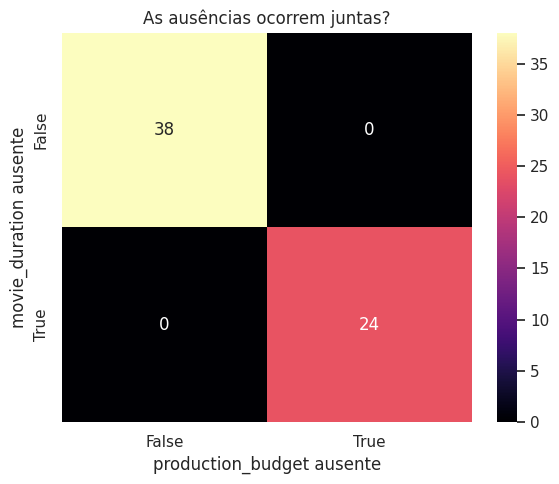

In [24]:
tabela_contingencia = pd.crosstab(df[cols_com_ausentes[0]].isna(), df[cols_com_ausentes[1]].isna(),
            rownames=[f"{cols_com_ausentes[0]} ausente"], colnames=[f"{cols_com_ausentes[1]} ausente"])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title("As ausências ocorrem juntas?")
plt.tight_layout()
plt.show()

**Pra discutir:** quantas linhas têm as duas colunas ausentes ao mesmo tempo? Isso muda a hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR), ou parecem eventos independentes?

*Relembrando:*
- MCAR: Mecanismo Aleatório e sem viés
- MAR: Mecanismo Randômico e com viés possível de corrigir
- MNAR: Mecanismo Não Randômico relacionada a própria feature

- *Se supormos que a ausência depende do próprio valor que está faltando*: por exemplo, a bilheteria não foi registrada porque o resultado foi tão baixo que a produção não divulgou os números, e o dado extra não seria relevante, isso seria classificado como **MNAR**.
- *Se supormos que a ausência depende de algo externo ao valor em si*: por exemplo, o formato da produção (série de TV) não prevê bilheteria de cinema, ou a plataforma de streaming não divulga métricas de audiência, independente do que o resultado provavelmente seria — isso seria classificado como **MAR** (ou até **MCAR**, se a decisão for arbitrária e não sistemática).

Aqui, diferente de outros casos, dá pra decidir olhando os dados: as 24 ausências coincidem exatamente com as séries de TV, e as cinco colunas faltam sempre juntas nas mesmas linhas. Isso descarta MNAR e aponta para uma ausência estrutural — a métrica não existe para aquele formato. Ainda assim, seguimos com a opção mais conservadora na hora de tratar.

**Nota para quando vocês replicarem no dataset de vocês:** se o dataset escolhido tiver *muitas* colunas com *muitos* ausentes, aí sim uma correlação (ou um heatmap) entre os indicadores de ausência passa a fazer sentido. O problema neste caso foi o volume pequeno, não a técnica em si.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [25]:
VARS_QUANT = ["tomato_meter", "audience_score", "movie_duration", "production_budget", "opening_weekend", "domestic_box_office", "worldwide_box_office"]
VARS_QUALI = ["mcu_phase"]

### Tabela descritiva, com assimetria e curtose

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
tomato_meter,82.63,86.00,12.72,46.00,99.00,-1.34,1.42
audience_score,81.21,86.00,14.04,32.00,98.00,-1.69,2.76
movie_duration,130.87,128.50,15.52,105.00,181.00,1.06,1.69
production_budget,203460526.32,200000000.00,55599239.44,130000000.00,365000000.00,1.39,2.04
opening_weekend,137733534.84,117336165.50,77280890.21,46110859.00,360091572.00,1.36,1.74
domestic_box_office,367125087.71,326105363.00,205421836.81,84500223.00,858400177.00,1.08,0.40
worldwide_box_office,913754990.00,767139114.00,582387060.75,206136825.00,2799439100.00,1.46,2.16


**Pra discutir:** olhando a tabela, quais variáveis já parecem assimétricas (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)?

Isso é coerente com o que vocês esperariam do mercado de cinema (ex: orçamento e bilheteria costumam ter poucos filmes com valores muito altos, os blockbusters, puxando a cauda direita)?

### Distribuições de dados

Onde fizer sentido, comparamos "Prejuízo" (azul) vs. "Lucrativo" (vermelho).
Vamos utilizar esta convenção de cor que vamos manter até a análise bivariada.


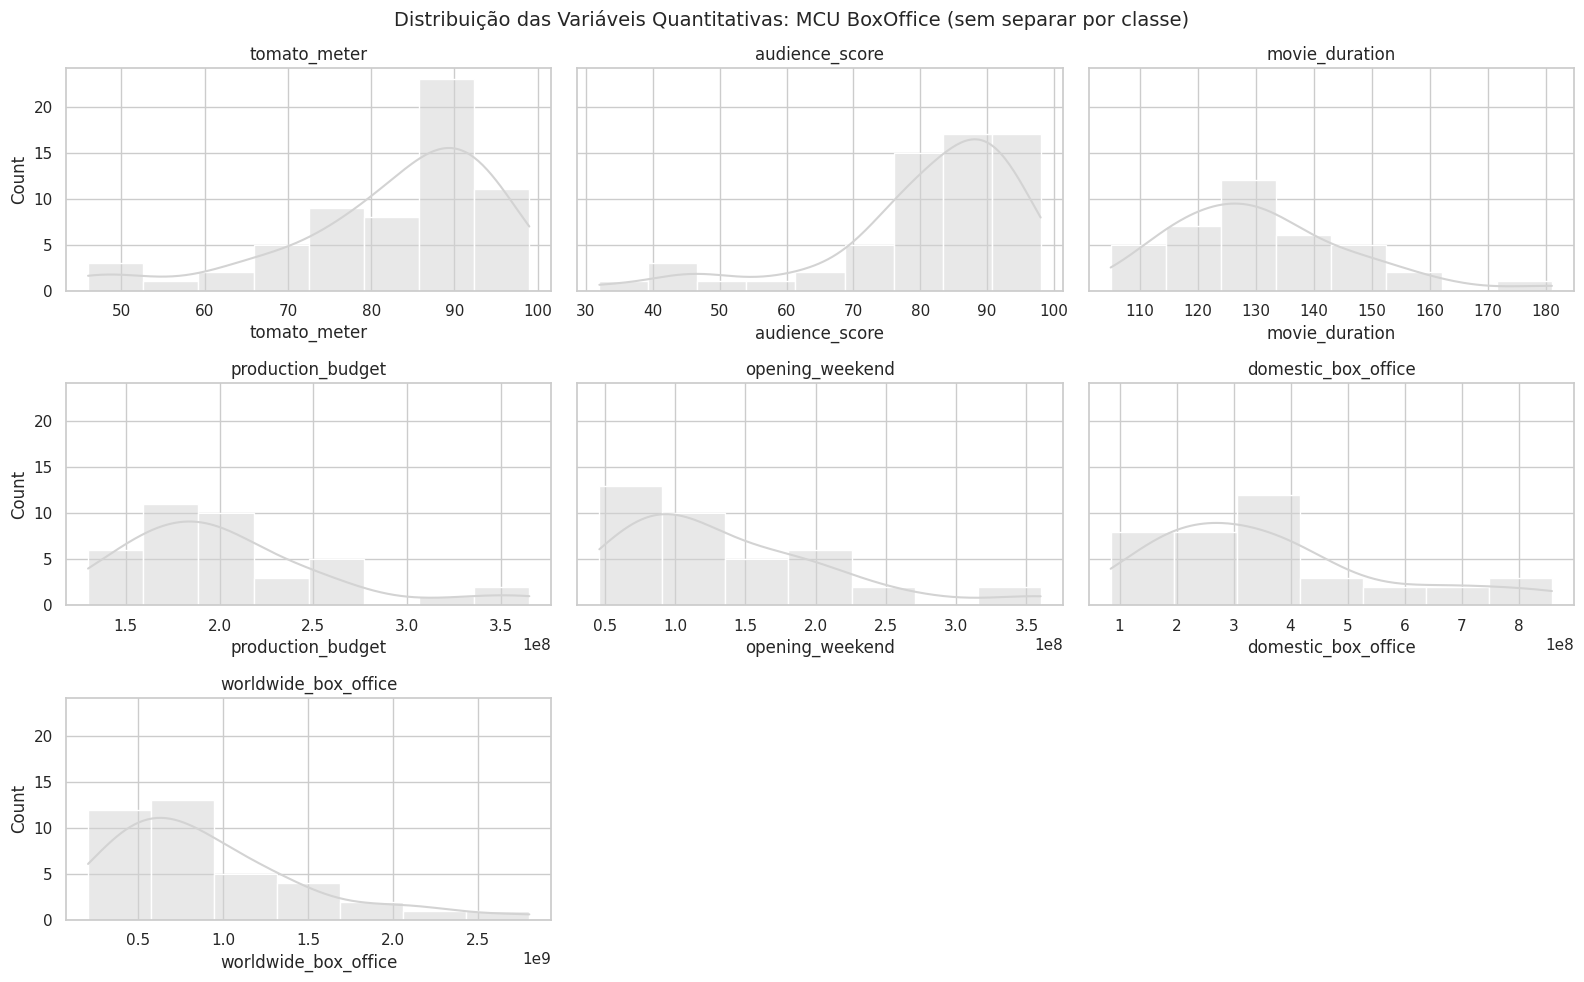

In [26]:
fig, axes = plt.subplots(3, 3, figsize=(16, 10), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas: MCU BoxOffice (sem separar por classe)", fontsize=14)
plt.tight_layout()
plt.show()

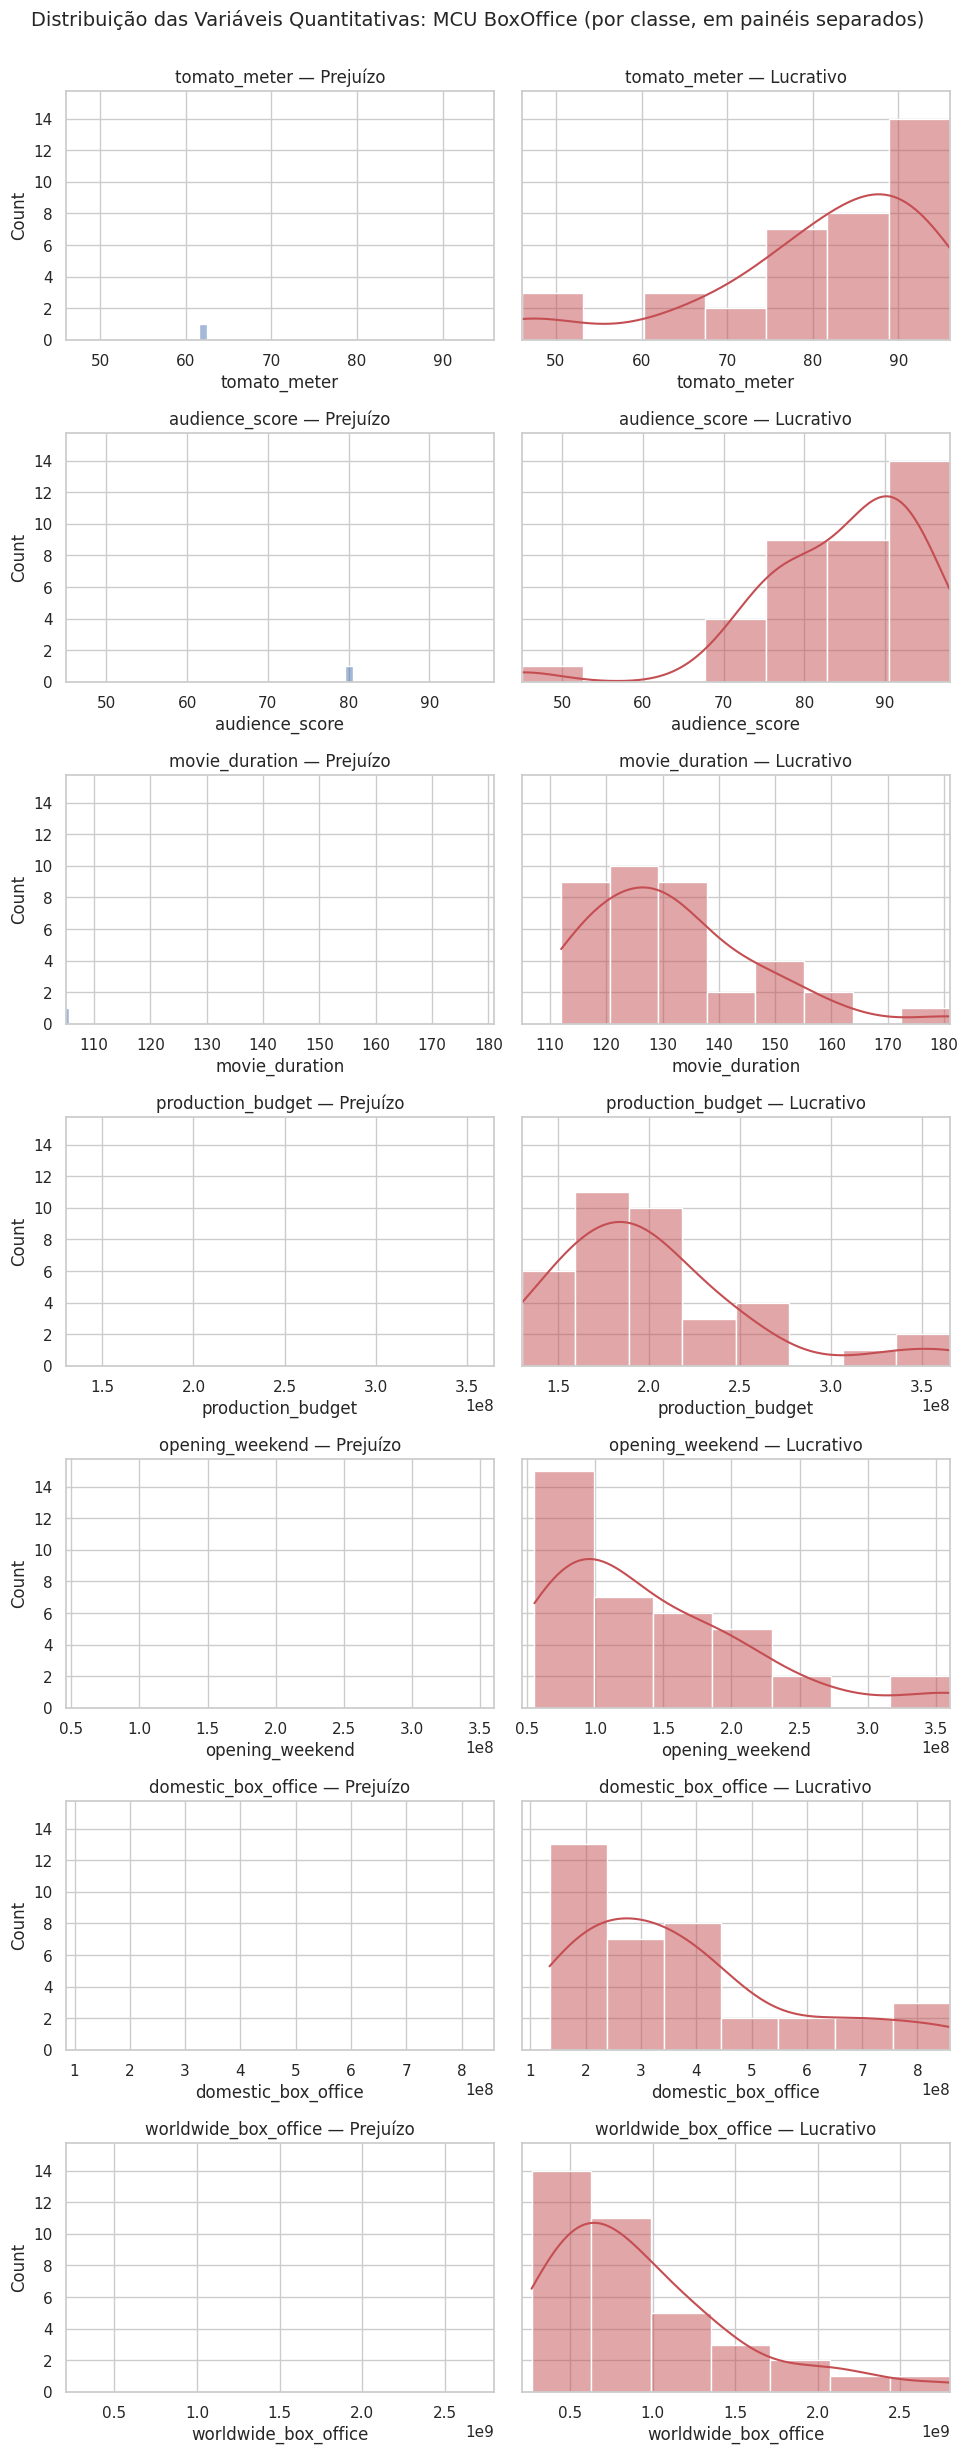

In [27]:
COR_CONTEXTO = "#4C72B0"   # ex: azul para "Prejuízo"
COR_DESTAQUE = "#C44E52"   # ex: vermelho para "Lucrativo"

df_filmes = df.dropna(subset=["worldwide_box_office", "production_budget"])

fig, axes = plt.subplots(len(VARS_QUANT), 2, figsize=(10, 3.5 * len(VARS_QUANT)), sharey=True)

for i, col in enumerate(VARS_QUANT):
    lim = (df_filmes[col].min(), df_filmes[col].max())
    for j, (classe, cor) in enumerate([("Prejuízo", COR_CONTEXTO), ("Lucrativo", COR_DESTAQUE)]):
        subset = df_filmes[df_filmes["resultado_financeiro"] == classe]
        sns.histplot(data=subset, x=col, kde=True, color=cor, ax=axes[i, j])
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}")

fig.suptitle("Distribuição das Variáveis Quantitativas: MCU BoxOffice (por classe, em painéis separados)", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()
df_filmes = df.dropna(subset=["worldwide_box_office", "production_budget"])

**Para discutir:** agora que as classes estão em painéis separados (mesma escala de eixo X em cada linha), fica mais fácil ver: alguma variável parece ter formato bem diferente entre "Prejuízo" e "Lucrativo"?

#### Testes de Aderência

*Será se a bilheteria mundial segue uma distribuição normal?*

O **Shapiro-Wilk** como o teste de aderência mais usado pra normalidade, junto com o **QQ-Plot** como visualização de apoio. Vamos testar com `worldwide_box_office`.

Shapiro-Wilk — worldwide_box_office: estatística=0.8679, p-valor=0.0003565
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


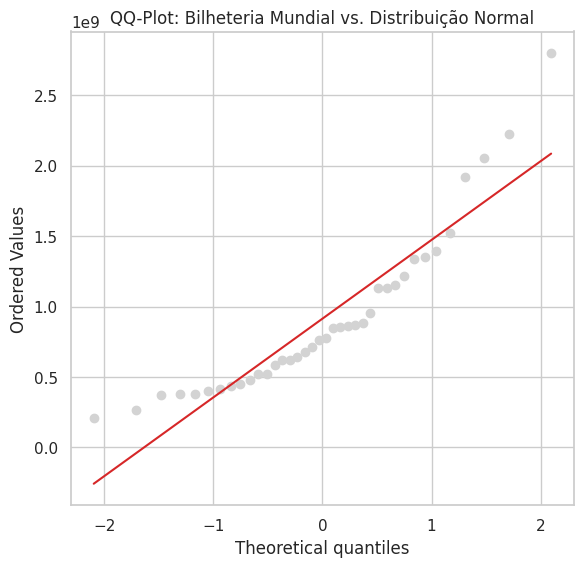

In [28]:
stat_sw, p_valor_sw = stats.shapiro(df_filmes["worldwide_box_office"].dropna())
print(f"Shapiro-Wilk — worldwide_box_office: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

"""### QQ-Plot — bilheteria mundial"""

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df_filmes["worldwide_box_office"].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: Bilheteria Mundial vs. Distribuição Normal")
plt.tight_layout()
plt.show()

**Como ler:** se os pontos (roxo) seguissem a reta vermelha de perto, a variável seguiria uma normal. Pontos que se afastam da reta nas pontas indicam cauda mais pesada ou mais leve que a normal — coerente com o resultado do Shapiro-Wilk acima.

**Nota: cuidado com duas armadilhas de interpretação**

- **Tamanho da amostra e poder do teste:** é comum achar que "poucos dados" tornam mais fácil rejeitar a normalidade e é o contrário. Amostras **pequenas** têm **menos poder estatístico**, ou seja, tendem a *não* rejeitar mesmo quando os dados realmente não são normais. Já amostras **muito grandes** (milhares de linhas) deixam o teste sensível demais, rejeitando por desvios triviais. Com n≈303 (nem pequeno, nem enorme) e três evidências concordando — skewness alto, QQ-Plot afastado da reta, e Shapiro-Wilk rejeitando — o resultado é razoavelmente confiável, não um artefato do tamanho da amostra.
- **Como afirmar o resultado:** quando o teste **rejeita** H0 (nosso caso, p < 0.05), a afirmação correta é "temos evidência estatística **contra** a normalidade" que é uma conclusão forte. A frase "não podemos garantir normalidade" cabe no caso oposto: quando o teste **não rejeita** H0, já que a ausência de rejeição nunca prova que os dados são normais, só que não há evidência suficiente contra.

In [29]:
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": round(p, 6), "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
tomato_meter,0.8697,0.000009,True
audience_score,0.8239,0.000000,True
movie_duration,0.9390,0.038950,True
production_budget,0.8699,0.000400,True
opening_weekend,0.8675,0.000347,True
domestic_box_office,0.8824,0.000842,True
worldwide_box_office,0.8679,0.000357,True


**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É especialmente útil pra comparar duas distribuições lado a lado — onde as curvas se distanciam mais é onde a diferença entre os grupos é mais perceptível.

Vamos ilustrar com uma única variável (`chol`, colesterol), só pra fixar como essa visualização se lê.

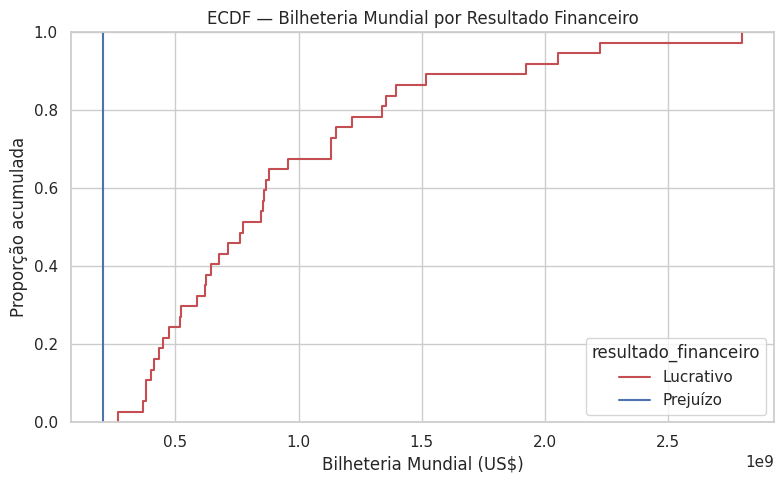

In [30]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df_filmes, x="worldwide_box_office", hue="resultado_financeiro",
             palette={"Prejuízo": COR_CONTEXTO, "Lucrativo": COR_DESTAQUE})
plt.title("ECDF — Bilheteria Mundial por Resultado Financeiro")
plt.xlabel("Bilheteria Mundial (US$)")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva diz "que fração dos pacientes desse grupo tem colesterol até aqui". Onde as duas curvas (rosa e roxa) se distanciam mais, ali está a faixa de colesterol onde os dois grupos mais diferem, sem precisar decidir uma largura de bin como no histograma.

### Métricas de Tendêncial Central

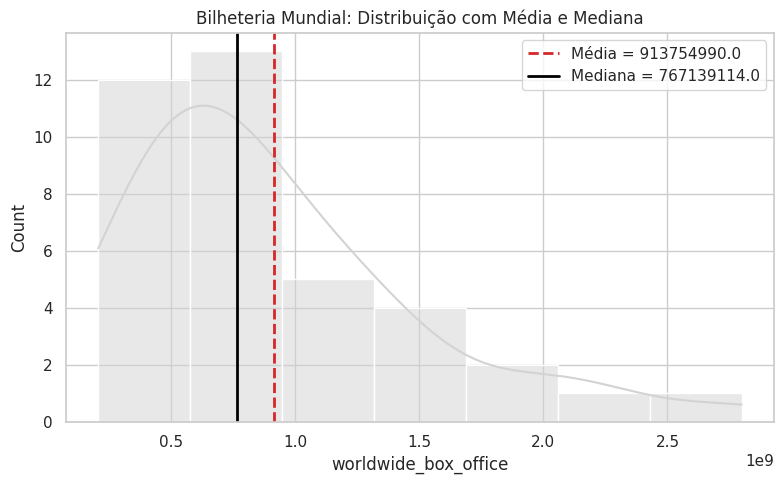

In [31]:
media_bo = df_filmes["worldwide_box_office"].mean()
mediana_bo = df_filmes["worldwide_box_office"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df_filmes, x="worldwide_box_office", kde=True, color=COR_NEUTRA)
plt.axvline(media_bo, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_bo:.1f}")
plt.axvline(mediana_bo, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_bo:.1f}")
plt.title("Bilheteria Mundial: Distribuição com Média e Mediana")
plt.legend()
plt.tight_layout()
plt.show()

### Dispersão

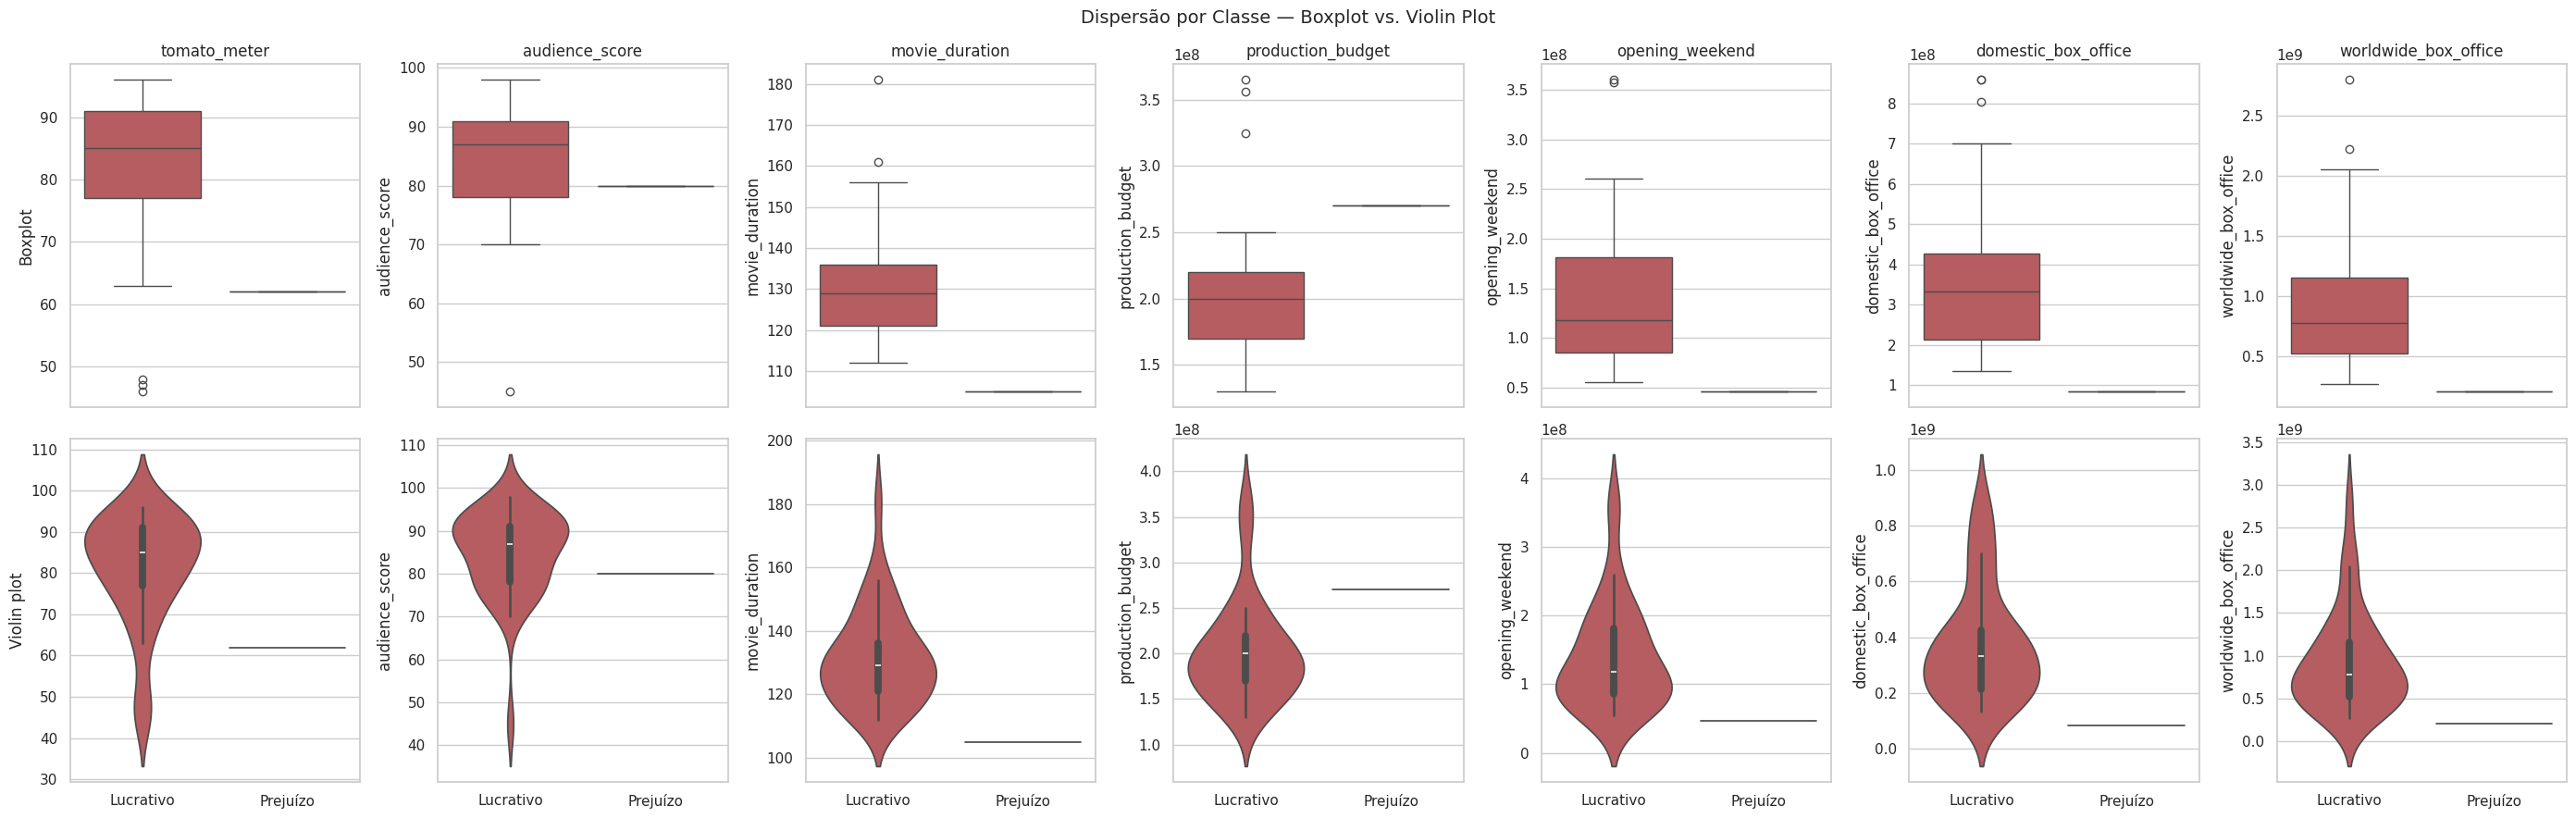

In [32]:
dispersao = df_filmes[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df_filmes[VARS_QUANT].quantile(0.75) - df_filmes[VARS_QUANT].quantile(0.25)
dispersao.round(2)

"""### Boxplot e violin plot por classe"""

palette_classe = {"Prejuízo": COR_CONTEXTO, "Lucrativo": COR_DESTAQUE}

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 9), sharex="col")

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df_filmes, x="resultado_financeiro", y=col, hue="resultado_financeiro",
                palette=palette_classe, legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df_filmes, x="resultado_financeiro", y=col, hue="resultado_financeiro",
                    palette=palette_classe, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Classe — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre "Normal" e "Cardíaco"? Isso já é um indício — antes mesmo da análise bivariada formal — de que essa variável pode ajudar a diferenciar as duas classes.

## 4. Tratamento de Dados Ausentes e Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), temos a informação que faltava pra decidir como tratar tanto os dados ausentes (`movie_duration`, `production_budget`, `opening_weekend`, `domestic_box_office`, `worldwide_box_office`) quanto os outliers das variáveis quantitativas. Depois do tratamento, vamos rodar a estatística descritiva mais uma vez ("depois") pra confirmar o efeito das escolhas e fechar o ciclo iterativo que começamos lá na abertura.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [33]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
tomato_meter,5.488000e+01,1.138800e+02,4.0
audience_score,5.412000e+01,1.131200e+02,5.0
movie_duration,9.288000e+01,1.618800e+02,1.0
production_budget,8.937500e+07,3.043750e+08,3.0
opening_weekend,-6.727363e+07,3.296275e+08,2.0
domestic_box_office,-1.134383e+08,7.447915e+08,3.0
worldwide_box_office,-5.047302e+08,2.139567e+09,2.0


### Visualizando os Outliers

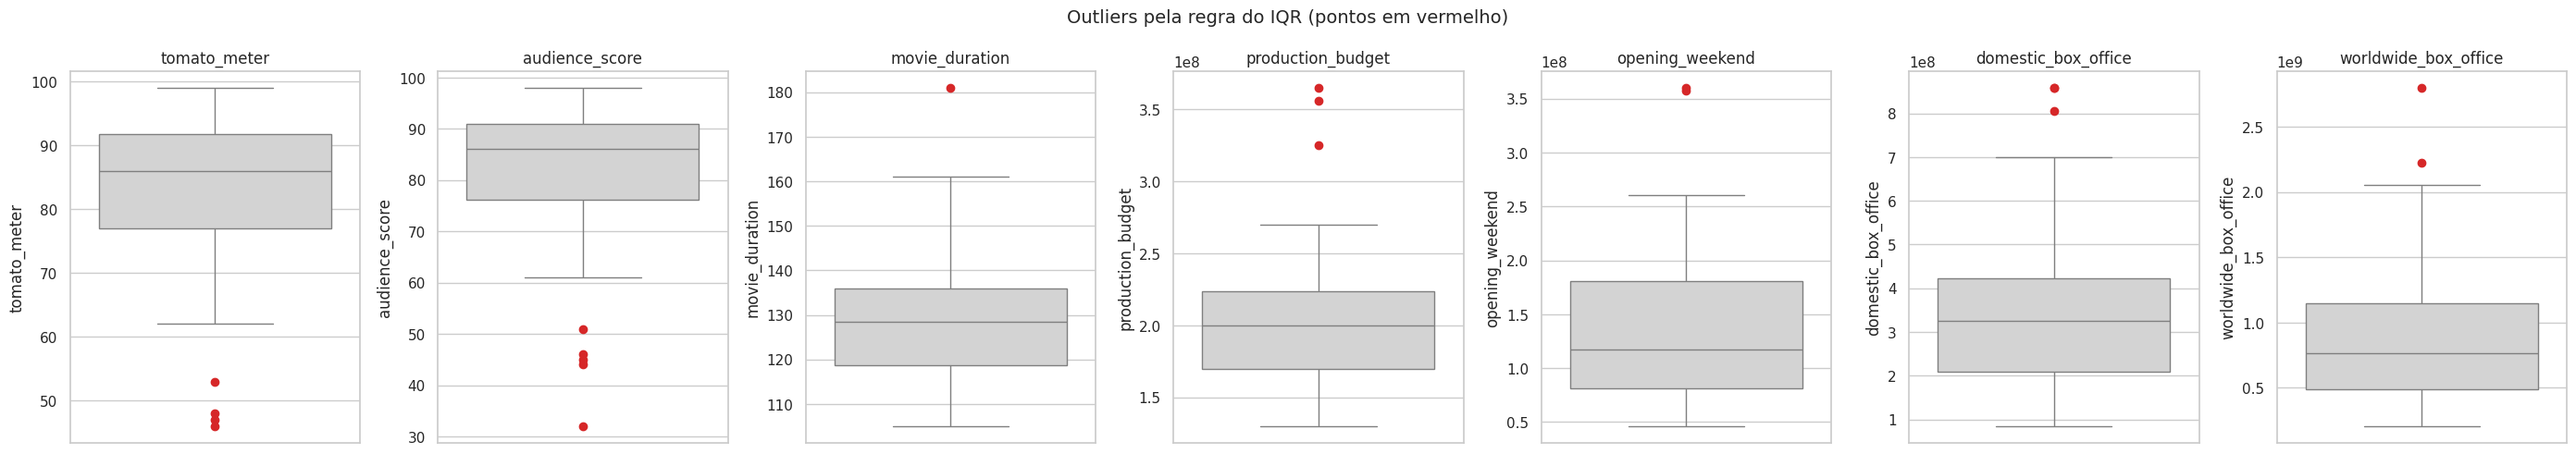

In [34]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** o slide 26 da aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

Olhando os outliers encontrados (principalmente em `worldwide_box_office` e `production_budget`): eles parecem financeiramente plausíveis (blockbusters reais podem ter bilheteria altíssima), ou parecem violar algum limite conhecido do mercado? Isso muda qual das três categorias se aplica — e, consequentemente, se devemos manter, transformar ou remover.

### Decidindo o Tratamento dos Dados Ausentes

Reunindo o que já discutimos: o mecanismo mais provável para as cinco colunas financeiras é MAR estrutural (não MNAR), e o volume é considerável (24 linhas em 62). Com essas duas informações juntas, a decisão pragmática é remover as linhas afetadas — o risco de viés é baixo (o mecanismo não depende do próprio valor ausente, e sim do formato da produção) e as linhas removidas são séries de TV, que não pertencem ao escopo de uma análise de bilheteria.

In [35]:
df_original = pd.read_csv(os.path.join(path, "mcu.csv"))
linhas_antes = df_original.shape[0]
df_antes = df_original.copy()

df = df_original.dropna(subset=["movie_duration", "production_budget", "opening_weekend", "domestic_box_office", "worldwide_box_office"]).reset_index(drop=True)
linhas_depois = df.shape[0]

print(f"Linhas antes: {linhas_antes} | Linhas depois: {linhas_depois} | Removidas: {linhas_antes - linhas_depois}")

Linhas antes: 62 | Linhas depois: 38 | Removidas: 24


### Decidindo o Tratamento dos Outliers

Diferente dos ausentes, aqui **não vamos remover automaticamente**. Pelos valores encontrados (dentro de faixas financeiramente plausíveis, ainda que raras), a classificação mais provável é **"Estatístico"**, outliers legítimos, não erros de coleta. Sendo assim, o tratamento recomendado nesse caso é **manter** (a informação é real e pode ser comercialmente relevante — por exemplo, exatamente os filmes com bilheteria mais extrema podem ser os de maior sucesso da franquia) ou, se for necessário para alguma técnica estatística específica mais à frente (ex: métodos sensíveis à assimetria), **transformar**.

Vamos manter os valores originais por enquanto, mas ilustrar como ficaria uma transformação logarítmica em `worldwide_box_office` — útil caso, mais adiante em análises futuras, a assimetria atrapalhe algum teste ou modelo.

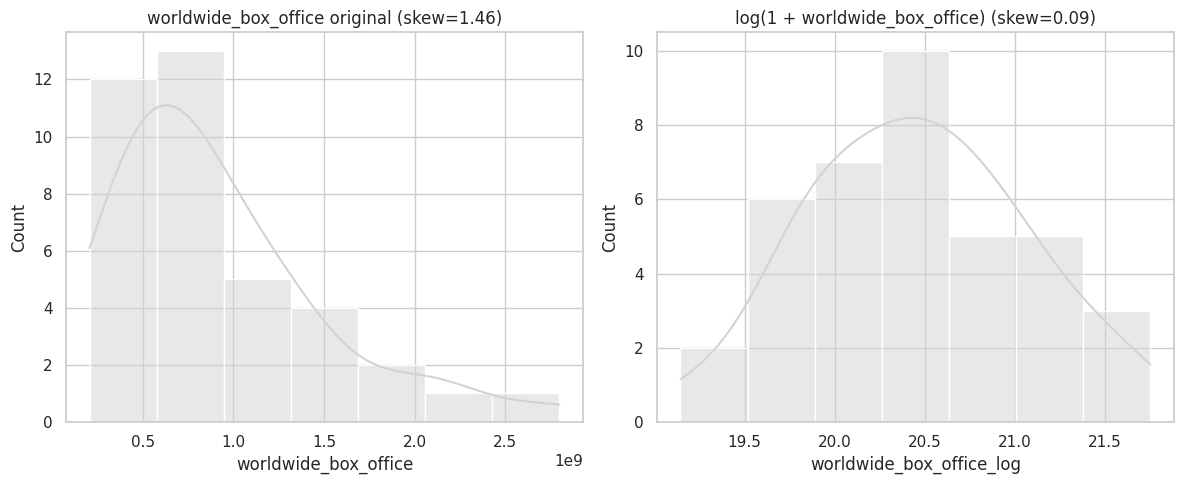

In [36]:
df["worldwide_box_office_log"] = np.log1p(df["worldwide_box_office"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="worldwide_box_office", kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"worldwide_box_office original (skew={df['worldwide_box_office'].skew():.2f})")

sns.histplot(data=df, x="worldwide_box_office_log", kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + worldwide_box_office) (skew={df['worldwide_box_office_log'].skew():.2f})")

plt.tight_layout()
plt.show()

**Pra discutir:** a transformação logarítmica reduziu visivelmente a assimetria? Mantivemos `worldwide_box_office_log` só como demonstração, mas não vamos usá-la nas próximas seções. A ideia foi mostrar como opção se fosse o objetivo de, por exemplo, alimentar um teste paramétrico que exige normalidade.

**Nota para quando vocês replicarem no dataset de vocês:** nem todo outlier deve ser removido. Antes de decidir, classifiquem: é um valor estatisticamente raro mas plausível (manter/transformar), viola alguma regra de negócio ou de mercado (investigar antes de decidir), ou é claramente um erro de digitação/coleta (corrigir ou remover)?

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [37]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
tomato_meter,80.42,84.50,13.37,46.00,96.00,-1.27,1.05
audience_score,84.61,87.00,10.05,45.00,98.00,-1.71,5.12
movie_duration,130.87,128.50,15.52,105.00,181.00,1.06,1.69
production_budget,203460526.32,200000000.00,55599239.44,130000000.00,365000000.00,1.39,2.04
opening_weekend,137733534.84,117336165.50,77280890.21,46110859.00,360091572.00,1.36,1.74
domestic_box_office,367125087.71,326105363.00,205421836.81,84500223.00,858400177.00,1.08,0.40
worldwide_box_office,913754990.00,767139114.00,582387060.75,206136825.00,2799439100.00,1.46,2.16


### Comparando "antes"x "depois""



In [38]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
tomato_meter,-1.337,-1.273,1.420,1.047,0.064,-0.372
audience_score,-1.688,-1.709,2.762,5.125,-0.022,2.363
movie_duration,1.059,1.059,1.693,1.693,-0.000,-0.000
production_budget,1.394,1.394,2.036,2.036,0.000,0.000
opening_weekend,1.361,1.361,1.740,1.740,0.000,0.000
domestic_box_office,1.079,1.079,0.400,0.400,0.000,0.000
worldwide_box_office,1.462,1.462,2.160,2.160,0.000,0.000


**Pra discutir:** os valores mudaram muito? Fazia sentido esperar uma diferença grande, considerando que removemos 39% das linhas e decidimos **não** alterar nenhum outlier? Esse resultado (praticamente nenhuma mudança) é, na verdade, uma confirmação de que o tratamento foi conservador — não um sinal de que ele não fez nada de útil.

**A bilheteria mundial ainda rejeita normalidade?**

Vamos rodar o mesmo Shapiro-Wilk da Seção 3, agora nos dados tratados.

In [39]:
import os
import pandas as pd
import numpy as np
from scipy import stats
import kagglehub

path = kagglehub.dataset_download("parthfr/marvel-cinematic-universe-boxoffice-csv")
df = pd.read_csv(os.path.join(path, "mcu.csv"))
df = df.dropna(subset=["movie_duration", "production_budget", "opening_weekend", "domestic_box_office", "worldwide_box_office"]).reset_index(drop=True)

df["resultado_financeiro"] = np.where(df["worldwide_box_office"] > df["production_budget"], "Lucrativo", "Prejuízo")
df["worldwide_box_office_log"] = np.log1p(df["worldwide_box_office"])

stat_sw_antes, p_valor_sw_antes = stats.shapiro(df["worldwide_box_office"])
stat_sw_depois, p_valor_sw_depois = stats.shapiro(df["worldwide_box_office_log"])

print("Shapiro-Wilk (antes) - worldwide_box_office: estatistica={:.4f}, p-valor={:.4g}".format(stat_sw_antes, p_valor_sw_antes))
print("Shapiro-Wilk (depois) - log(1 + worldwide_box_office): estatistica={:.4f}, p-valor={:.4g}".format(stat_sw_depois, p_valor_sw_depois))

Using Colab cache for faster access to the 'marvel-cinematic-universe-boxoffice-csv' dataset.
Shapiro-Wilk (antes) - worldwide_box_office: estatistica=0.8679, p-valor=0.0003565
Shapiro-Wilk (depois) - log(1 + worldwide_box_office): estatistica=0.9895, p-valor=0.9734


**Visualizando antes x depois, lado a lado**

Vamos sobrepor as distribuições de duas variáveis que mais chamaram atenção na Seção 4 (`worldwide_box_office` e `production_budget`), comparando a versão original (`df_antes`) com a tratada (`df`).

Using Colab cache for faster access to the 'marvel-cinematic-universe-boxoffice-csv' dataset.


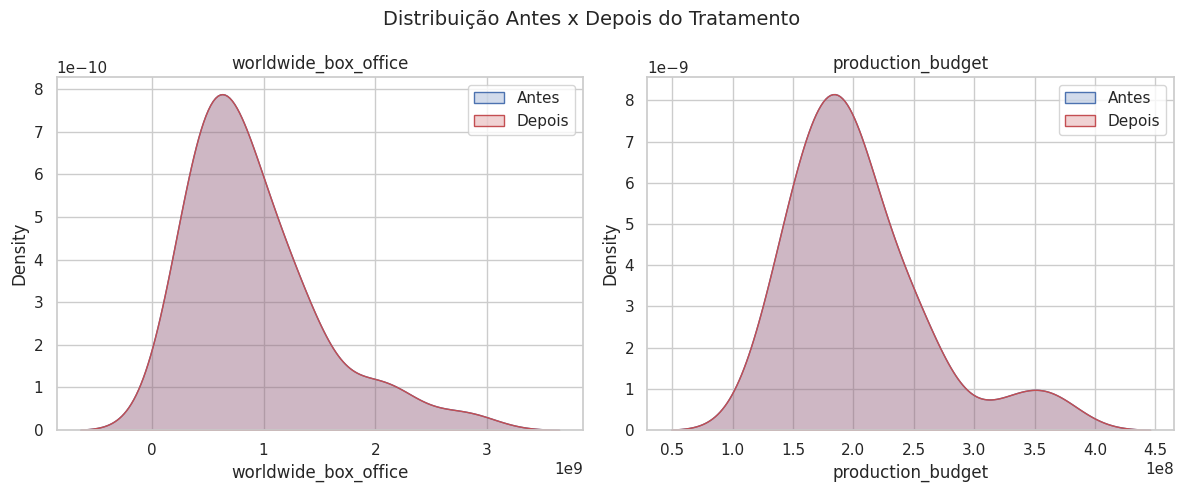

In [40]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub


path = kagglehub.dataset_download("parthfr/marvel-cinematic-universe-boxoffice-csv")

df_antes = pd.read_csv(os.path.join(path, "mcu.csv"))
df = df_antes.dropna(subset=["movie_duration", "production_budget", "opening_weekend", "domestic_box_office", "worldwide_box_office"]).reset_index(drop=True)
df["resultado_financeiro"] = np.where(df["worldwide_box_office"] > df["production_budget"], "Lucrativo", "Prejuízo")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, ["worldwide_box_office", "production_budget"]):
    sns.kdeplot(df_antes[col], color=COR_CONTEXTO, fill=True, label="Antes", ax=ax)
    sns.kdeplot(df[col], color=COR_DESTAQUE, fill=True, label="Depois", ax=ax)
    ax.set_title(col)
    ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** as curvas "antes" e "depois" praticamente se sobrepõem? Isso é o esperado aqui, já que removemos poucas linhas e não tocamos nos outliers.

Guardem essa observação: em datasets onde o volume de ausentes/outliers for maior, essa mesma comparação pode mostrar uma diferença bem mais visível e sempre que essa checagem "antes x depois" que confirma (ou não) que o tratamento teve o efeito esperado, em vez de assumir isso às cegas.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [41]:
VARS_QUALI = ["mcu_phase", "resultado_financeiro"]

for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))


--- mcu_phase ---
           absoluta  relativa
mcu_phase                    
Phase 3          11     0.289
Phase 4           7     0.184
Phase 2           6     0.158
Phase 1           6     0.158
Phase 5           6     0.158
Phase 6           2     0.053

--- resultado_financeiro ---
                      absoluta  relativa
resultado_financeiro                    
Lucrativo                   37     0.974
Prejuízo                     1     0.026


#### Visualizando as frequências

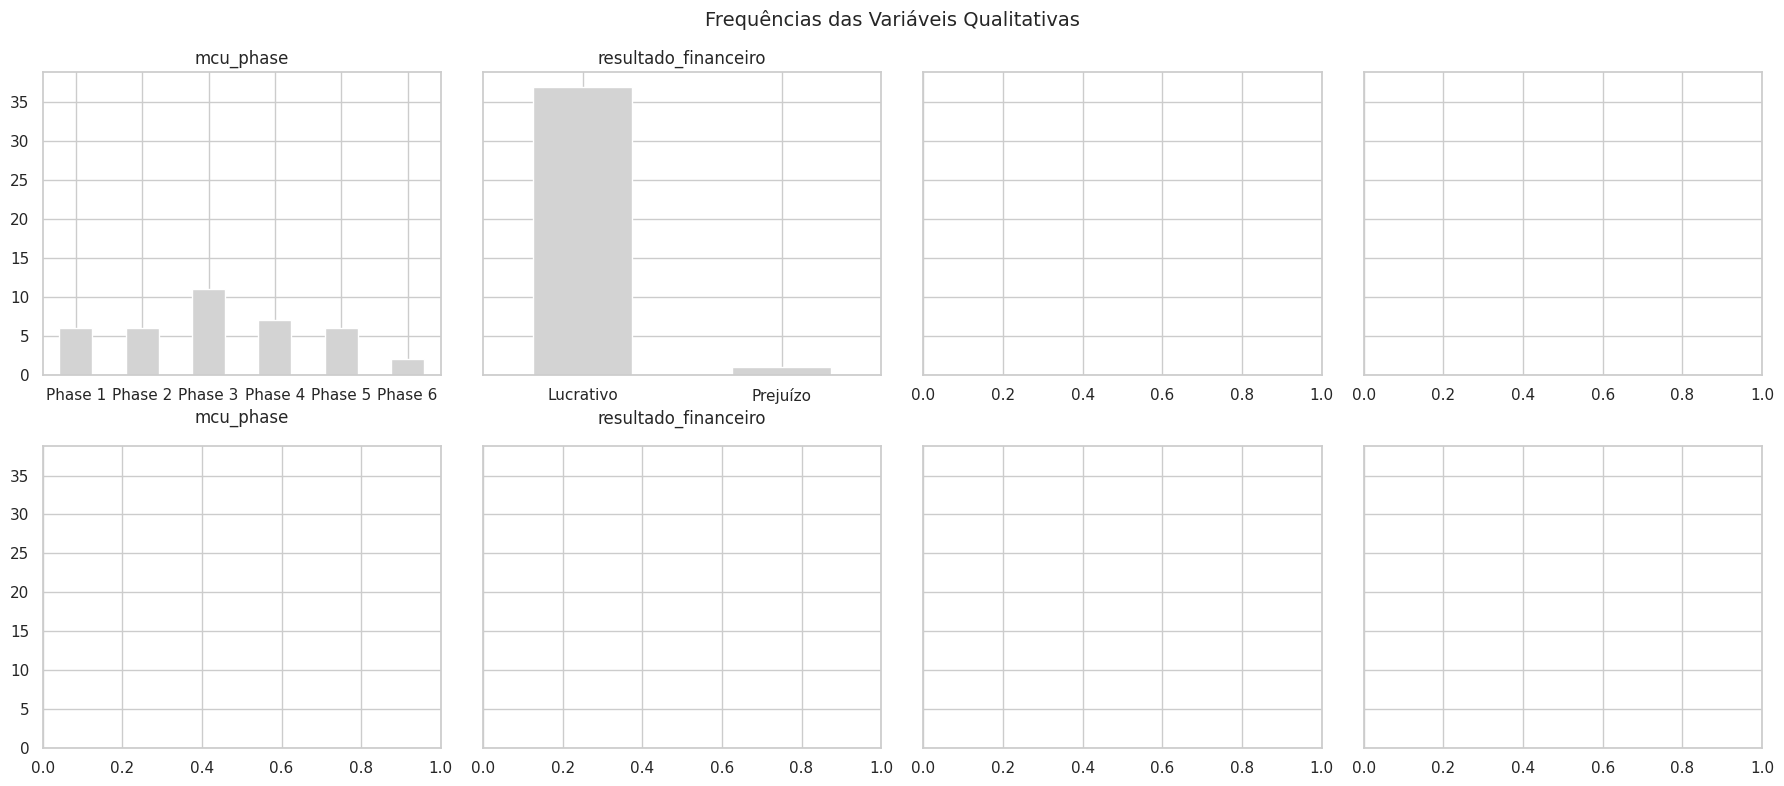

In [42]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUALI):
    df[col].value_counts().sort_index().plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=0)

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase todas as observações)? Isso pode impactar como vamos interpretar cruzamentos com essa variável mais na frente na análise bivariada.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Vamos aplicar as duas em todas as qualitativas, incluindo o próprio alvo `resultado_financeiro`.

In [43]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

vars_para_checar = VARS_QUALI
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
mcu_phase,6.0,5.5,0.949
resultado_financeiro,2.0,37.0,0.176


**Pra discutir:** alguma variável está com entropia bem próxima de 0 (bem desbalanceada)? E o próprio alvo `resultado_financeiro` — está balanceado o suficiente pra não distorcer a análise bivariada e um eventual modelo mais à frente?

### Análise Bivariada

Agora começamos a avaliar como as variáveis de fato se relacionam entre si e com o alvo 'doença cardíaca'.

#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das nossas variáveis passou no Shapiro-Wilk, Spearman é a escolha mais segura aqui, mas vamos calcular as três para comparar.

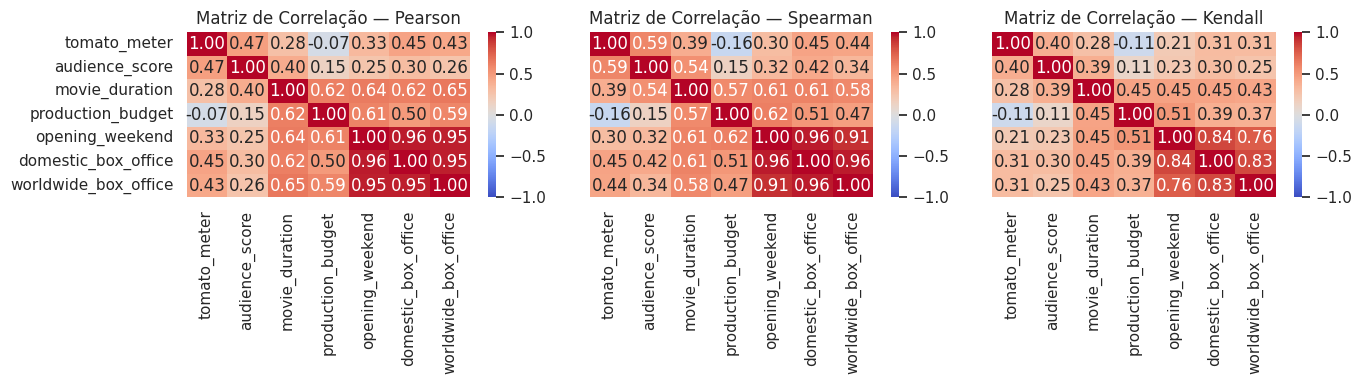

In [44]:
VARS_QUANT = ["tomato_meter", "audience_score", "movie_duration", "production_budget", "opening_weekend", "domestic_box_office", "worldwide_box_office"]

corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Matriz de Correlação — Pearson")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Matriz de Correlação — Spearman")
sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[2])
ax[2].set_title("Matriz de Correlação — Kendall")
plt.tight_layout()
plt.show()

Como os dados do triângulo superior e inferior são simétricos, poderíamos plotar a matriz de correlação da seguinte forma.

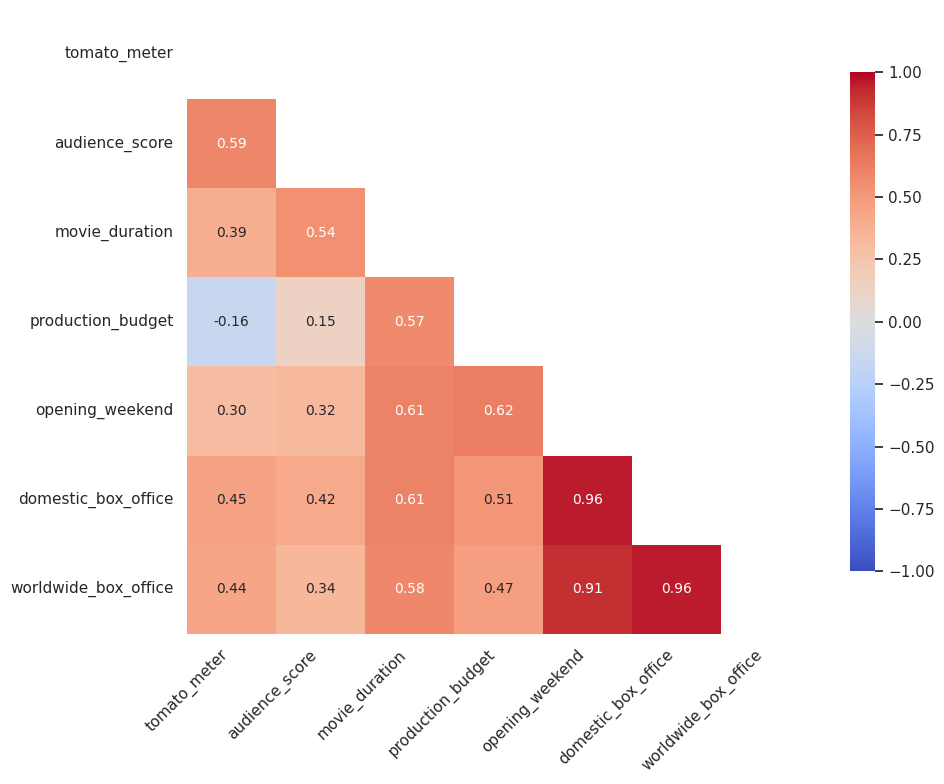

In [45]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(10, 8))
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm", fmt=".2f", square=True, vmin=-1, vmax=1,
            annot_kws={"size": 10}, cbar_kws={"shrink": 0.8})
plt.grid(False)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

**Pra discutir:** Pearson e Spearman divergem bastante em algum par de variáveis? Se sim, isso é um sinal de relação não-linear (monotônica, mas não em linha reta) em que Spearman capturaria e Pearson não.

#### Dispersão (scatter) entre duas variáveis quantitativas

Escolhemos `production_budget` x `worldwide_box_office` por um motivo de domínio, não só estatístico: existe uma relação comercial entre orçamento e bilheteria, o que torna esse par um bom candidato pra visualizar uma tendência real.

**Nota para quando vocês replicarem no dataset de vocês:** nem sempre vai existir uma relação de domínio óbvia e, nesse caso, uma alternativa é escolher o par com o maior |correlação| na tabela acima, deixando a própria estatística guiar a escolha.

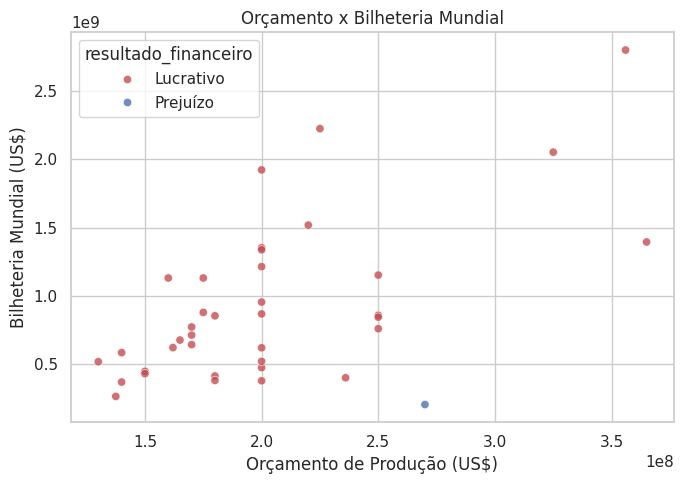

In [46]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="production_budget", y="worldwide_box_office", hue="resultado_financeiro",
                palette={"Prejuízo": COR_CONTEXTO, "Lucrativo": COR_DESTAQUE}, alpha=0.8)
plt.title("Orçamento x Bilheteria Mundial")
plt.xlabel("Orçamento de Produção (US$)")
plt.ylabel("Bilheteria Mundial (US$)")
plt.tight_layout()
plt.show()

**Pra discutir:** existe uma tendência visível (conforme o orçamento aumenta, `worldwide_box_office` tende a subir)? As duas classes ocupam regiões diferentes do gráfico, ou estão misturadas?

#### Quantitativa x Qualitativa: Comparando Grupos

Na aula passada listamos **T-Test** (2 grupos) e **ANOVA** (3+ grupos) como testes paramétricos pra comparar uma variável quantitativa entre categorias, mas os dois assumem normalidade dentro de cada grupo.

Já vimos na Seção 3 (tabela generalizada do Shapiro-Wilk) que **nenhuma** das nossas quantitativas passou nesse teste. Isso significa que, tecnicamente, deveríamos usar os equivalentes **não-paramétricos**: **Mann-Whitney U** no lugar do T-Test, e **Kruskal-Wallis** no lugar da ANOVA. Vamos calcular os dois lado a lado pra comparar, mas o resultado não-paramétrico é o que deveríamos reportar como principal.

In [47]:
resultados_comparacao = []
for col in VARS_QUANT:
    grupo_prejuizo = df.loc[df["resultado_financeiro"] == "Prejuízo", col]
    grupo_lucrativo = df.loc[df["resultado_financeiro"] == "Lucrativo", col]

    stat_t, p_t = stats.ttest_ind(grupo_prejuizo, grupo_lucrativo, equal_var=False)  # Welch (paramétrico)
    stat_u, p_u = stats.mannwhitneyu(grupo_prejuizo, grupo_lucrativo)  # não-paramétrico

    resultados_comparacao.append({
        "variavel": col,
        "p_valor_ttest": round(p_t, 5),
        "p_valor_mannwhitney": round(p_u, 5),
        "concordam": (p_t < 0.05) == (p_u < 0.05),
    })

pd.DataFrame(resultados_comparacao).set_index("variavel")

,p_valor_ttest,p_valor_mannwhitney,concordam
variavel,,,
tomato_meter,NaN,0.17100,True
audience_score,NaN,0.55261,True
movie_duration,NaN,0.10044,True
production_budget,NaN,0.16697,True
opening_weekend,NaN,0.05263,True
domestic_box_office,NaN,0.05263,True
worldwide_box_office,NaN,0.05263,True


**Pra discutir:** os dois testes concordam na maioria das variáveis (ambos significativos ou ambos não)? Quando divergem, é o **Mann-Whitney** que deveríamos priorizar, é o que respeita a premissa que de fato temos (dados não-normais), não a que gostaríamos de ter.

**Nota:** mantivemos o T-Test aqui só como contraste pedagógico. Reportar apenas o T-Test, sem essa ressalva, seria estatisticamente inconsistente com o que a própria Seção 3 já mostrou sobre a normalidade dessas variáveis.

*Exemplo com 3+ grupos — ANOVA x Kruskal-Wallis*

`mcu_phase` (fase do MCU) tem várias categorias. Pelo mesmo motivo acima, calculamos a ANOVA (paramétrico) e o **Kruskal-Wallis** (não-paramétrico, equivalente pra 3+ grupos) lado a lado.

ANOVA — worldwide_box_office entre fases do MCU: estatística=1.683, p-valor=0.1672
Kruskal-Wallis — worldwide_box_office entre fases do MCU: estatística=10.143, p-valor=0.071276


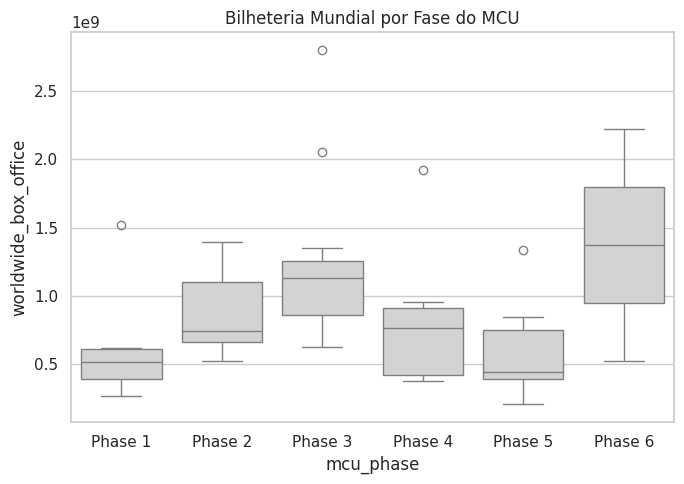

In [48]:
grupos_fase = [grupo["worldwide_box_office"].values for _, grupo in df.groupby("mcu_phase")]

stat_anova, p_anova = stats.f_oneway(*grupos_fase)  # paramétrico
stat_kw, p_kw = stats.kruskal(*grupos_fase)  # não-paramétrico

print(f"ANOVA — worldwide_box_office entre fases do MCU: estatística={stat_anova:.3f}, p-valor={p_anova:.5g}")
print(f"Kruskal-Wallis — worldwide_box_office entre fases do MCU: estatística={stat_kw:.3f}, p-valor={p_kw:.5g}")

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="mcu_phase", y="worldwide_box_office", color=COR_NEUTRA)
plt.title("Bilheteria Mundial por Fase do MCU")
plt.tight_layout()
plt.show()

**Pra discutir:** o Kruskal-Wallis concorda com a ANOVA sobre existir diferença entre pelo menos uma categoria de `mcu_phase`? Como já sabemos que `worldwide_box_office` não é normal, o **Kruskal-Wallis** é o resultado que deveríamos reportar como principal, a ANOVA fica só como contraste.

#### Quantitativa x Qualitativa

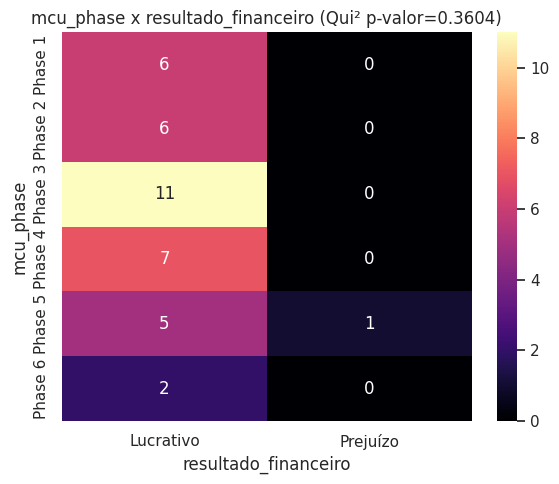

In [49]:
contingencia_fase = pd.crosstab(df["mcu_phase"], df["resultado_financeiro"])
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_fase)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(contingencia_fase, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title(f"mcu_phase x resultado_financeiro (Qui² p-valor={p_chi2:.4g})")
plt.tight_layout()
plt.show()

**Pra discutir:** o p-valor do Qui-Quadrado indica que `mcu_phase` e `resultado_financeiro` são independentes, ou há associação estatisticamente significativa entre elas?

#### Avaliação de Fairness

Olhar o desbalanceamento da base inteira é só metade da história. Uma pergunta recorrente em discussões de **fairness** (justiça algorítmica) é: será que a distribuição do desfecho se comporta igual em diferentes subgrupos de atributos sensíveis (década e faixa de orçamento, no nosso caso)? Se não, isso pode refletir um padrão real (ex: orçamentos muito altos exigem bilheteria maior para gerar lucro) ou um viés na forma como os dados foram coletados — de qualquer forma, é algo que vale mapear **antes** de qualquer modelagem.

In [50]:
df["decada"] = pd.cut(pd.to_datetime(df["release_date"]).dt.year, bins=[2007, 2012, 2017, 2022, 2030],
                      labels=["2008-2012", "2013-2017", "2018-2022", "2023+"])
df["faixa_orcamento"] = pd.cut(df["production_budget"], bins=[0, 150e6, 200e6, 250e6, 1e9],
                               labels=["<150M", "150-200M", "200-250M", "250M+"])

print("Desbalanceamento — década de lançamento:")
print(metrica_desbalanceamento(df["decada"]))
print("\nDesbalanceamento — faixa de orçamento:")
print(metrica_desbalanceamento(df["faixa_orcamento"]))

Desbalanceamento — década de lançamento:
n_classes                 4.00
razao_desbalanceamento    2.17
entropia_normalizada      0.97
dtype: float64

Desbalanceamento — faixa de orçamento:
n_classes                 4.000
razao_desbalanceamento    5.250
entropia_normalizada      0.842
dtype: float64


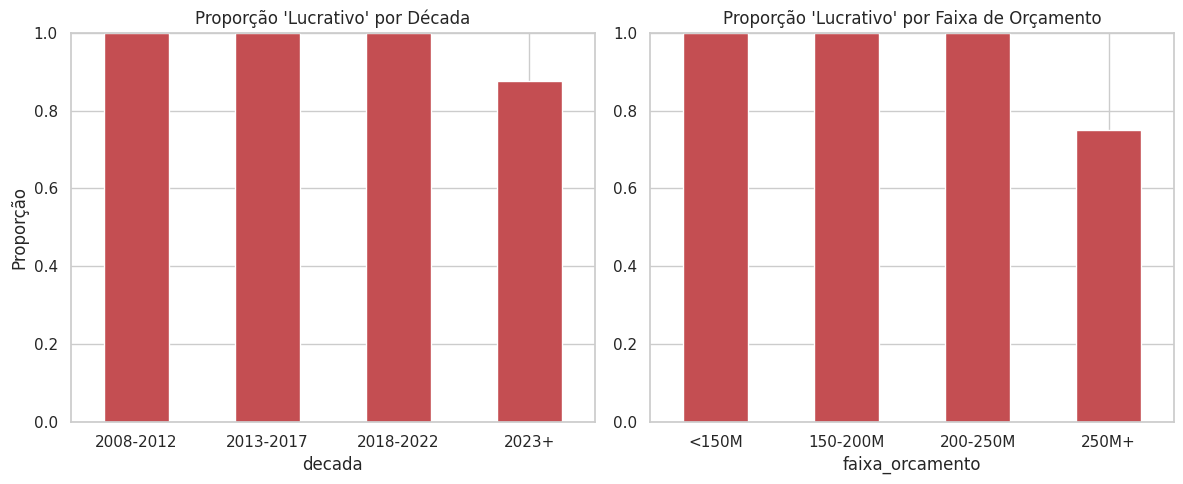

In [51]:
prop_por_decada = pd.crosstab(df["decada"], df["resultado_financeiro"], normalize="index").round(3)
prop_por_faixa = pd.crosstab(df["faixa_orcamento"], df["resultado_financeiro"], normalize="index").round(3)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

prop_por_decada["Lucrativo"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[0])
axes[0].set_title("Proporção 'Lucrativo' por Década")
axes[0].set_ylabel("Proporção")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=0)

prop_por_faixa["Lucrativo"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[1])
axes[1].set_title("Proporção 'Lucrativo' por Faixa de Orçamento")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Pra discutir:** a proporção de filmes lucrativos varia bastante entre década e faixa de orçamento? Isso pode refletir um padrão de mercado real e bem documentado (ex: filmes de orçamento muito alto precisam de bilheteria maior para se pagar), ou pode ser um artefato de **quais** produções a Marvel escolheu lançar em cada período. A pergunta "a distribuição do desfecho é uniforme entre os grupos?" é o ponto de partida de várias discussões de fairness em ciência de dados, e não tem uma resposta única: depende do contexto e da causa por trás da disparidade.

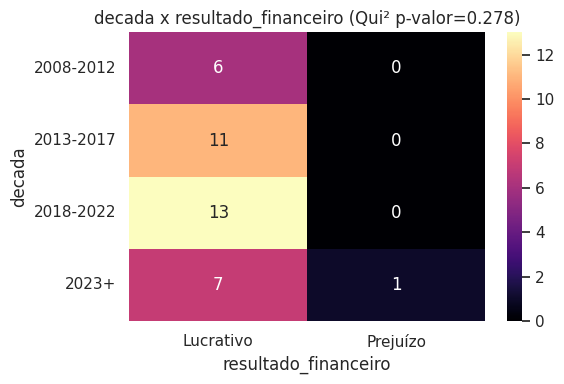

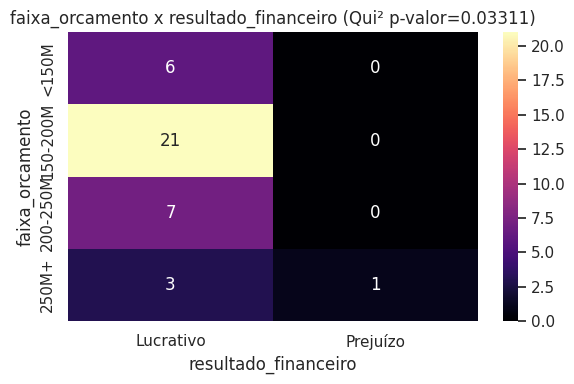

In [52]:
for atributo in ["decada", "faixa_orcamento"]:
    contingencia = pd.crosstab(df[atributo], df["resultado_financeiro"])
    chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)

    fig, ax = plt.subplots(figsize=(6, 4))
    sns.heatmap(contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title(f"{atributo} x resultado_financeiro (Qui² p-valor={p_valor:.4g})")
    plt.tight_layout()
    plt.show()

**Pra discutir:** o Qui-Quadrado confirma associação estatisticamente significativa entre década/faixa de orçamento e o desfecho? Lembrando que mesmo que a associação seja estatisticamente significativa, isso não diz *por que* ela existe — pode ser um fator de mercado real (orçamentos altos exigem bilheteria maior), pode ser um viés de quais produções a Marvel escolheu lançar em cada período (possivelmente década), ou uma mistura das duas coisas. Um teste estatístico aponta *que* existe associação, não *a causa* dela — essa distinção é o núcleo de qualquer discussão séria de fairness.

#### Outliers bivariados

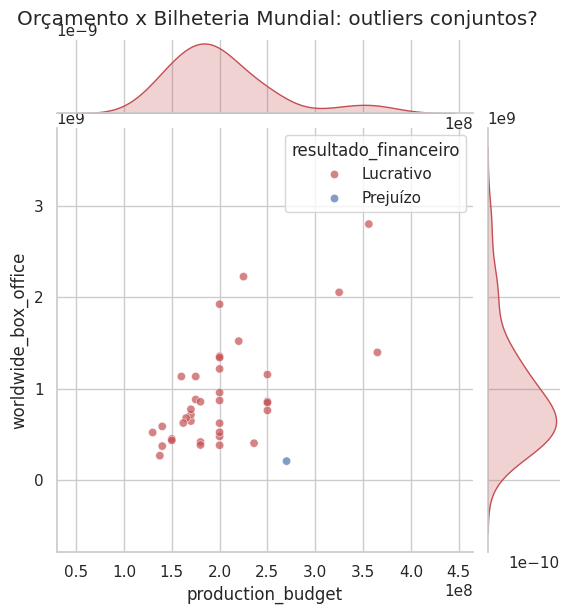

In [54]:
sns.jointplot(data=df, x="production_budget", y="worldwide_box_office", hue="resultado_financeiro",
              palette={"Prejuízo": COR_CONTEXTO, "Lucrativo": COR_DESTAQUE}, alpha=0.7, height=6)
plt.suptitle("Orçamento x Bilheteria Mundial: outliers conjuntos?", y=1.02)
plt.show()

**Pra discutir:** existe algum ponto que não parecia outlier nos histogramas univariados (Seção 3/4), mas que se destaca aqui como uma combinação incomum de `production_budget` e `worldwide_box_office`?

#### Análise Multivariada

##### Matriz de Correlação

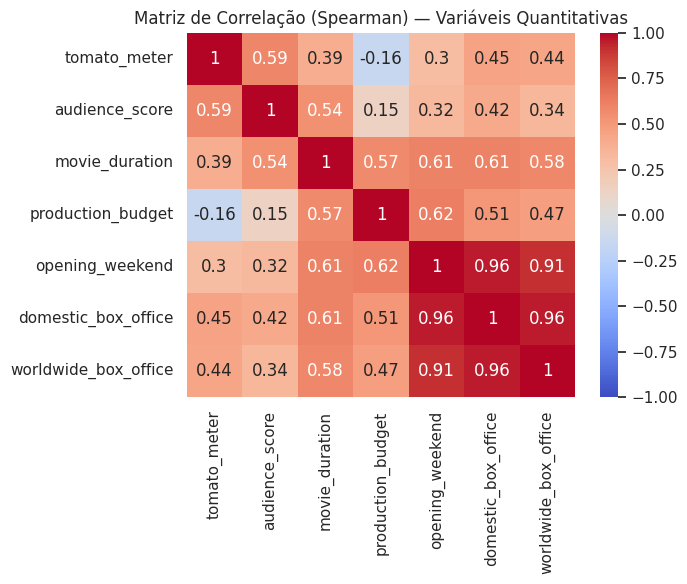

In [55]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()


**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?

##### Correlograma

Text(0.5, 1.02, 'Correlograma: Dispersão × Correlação')

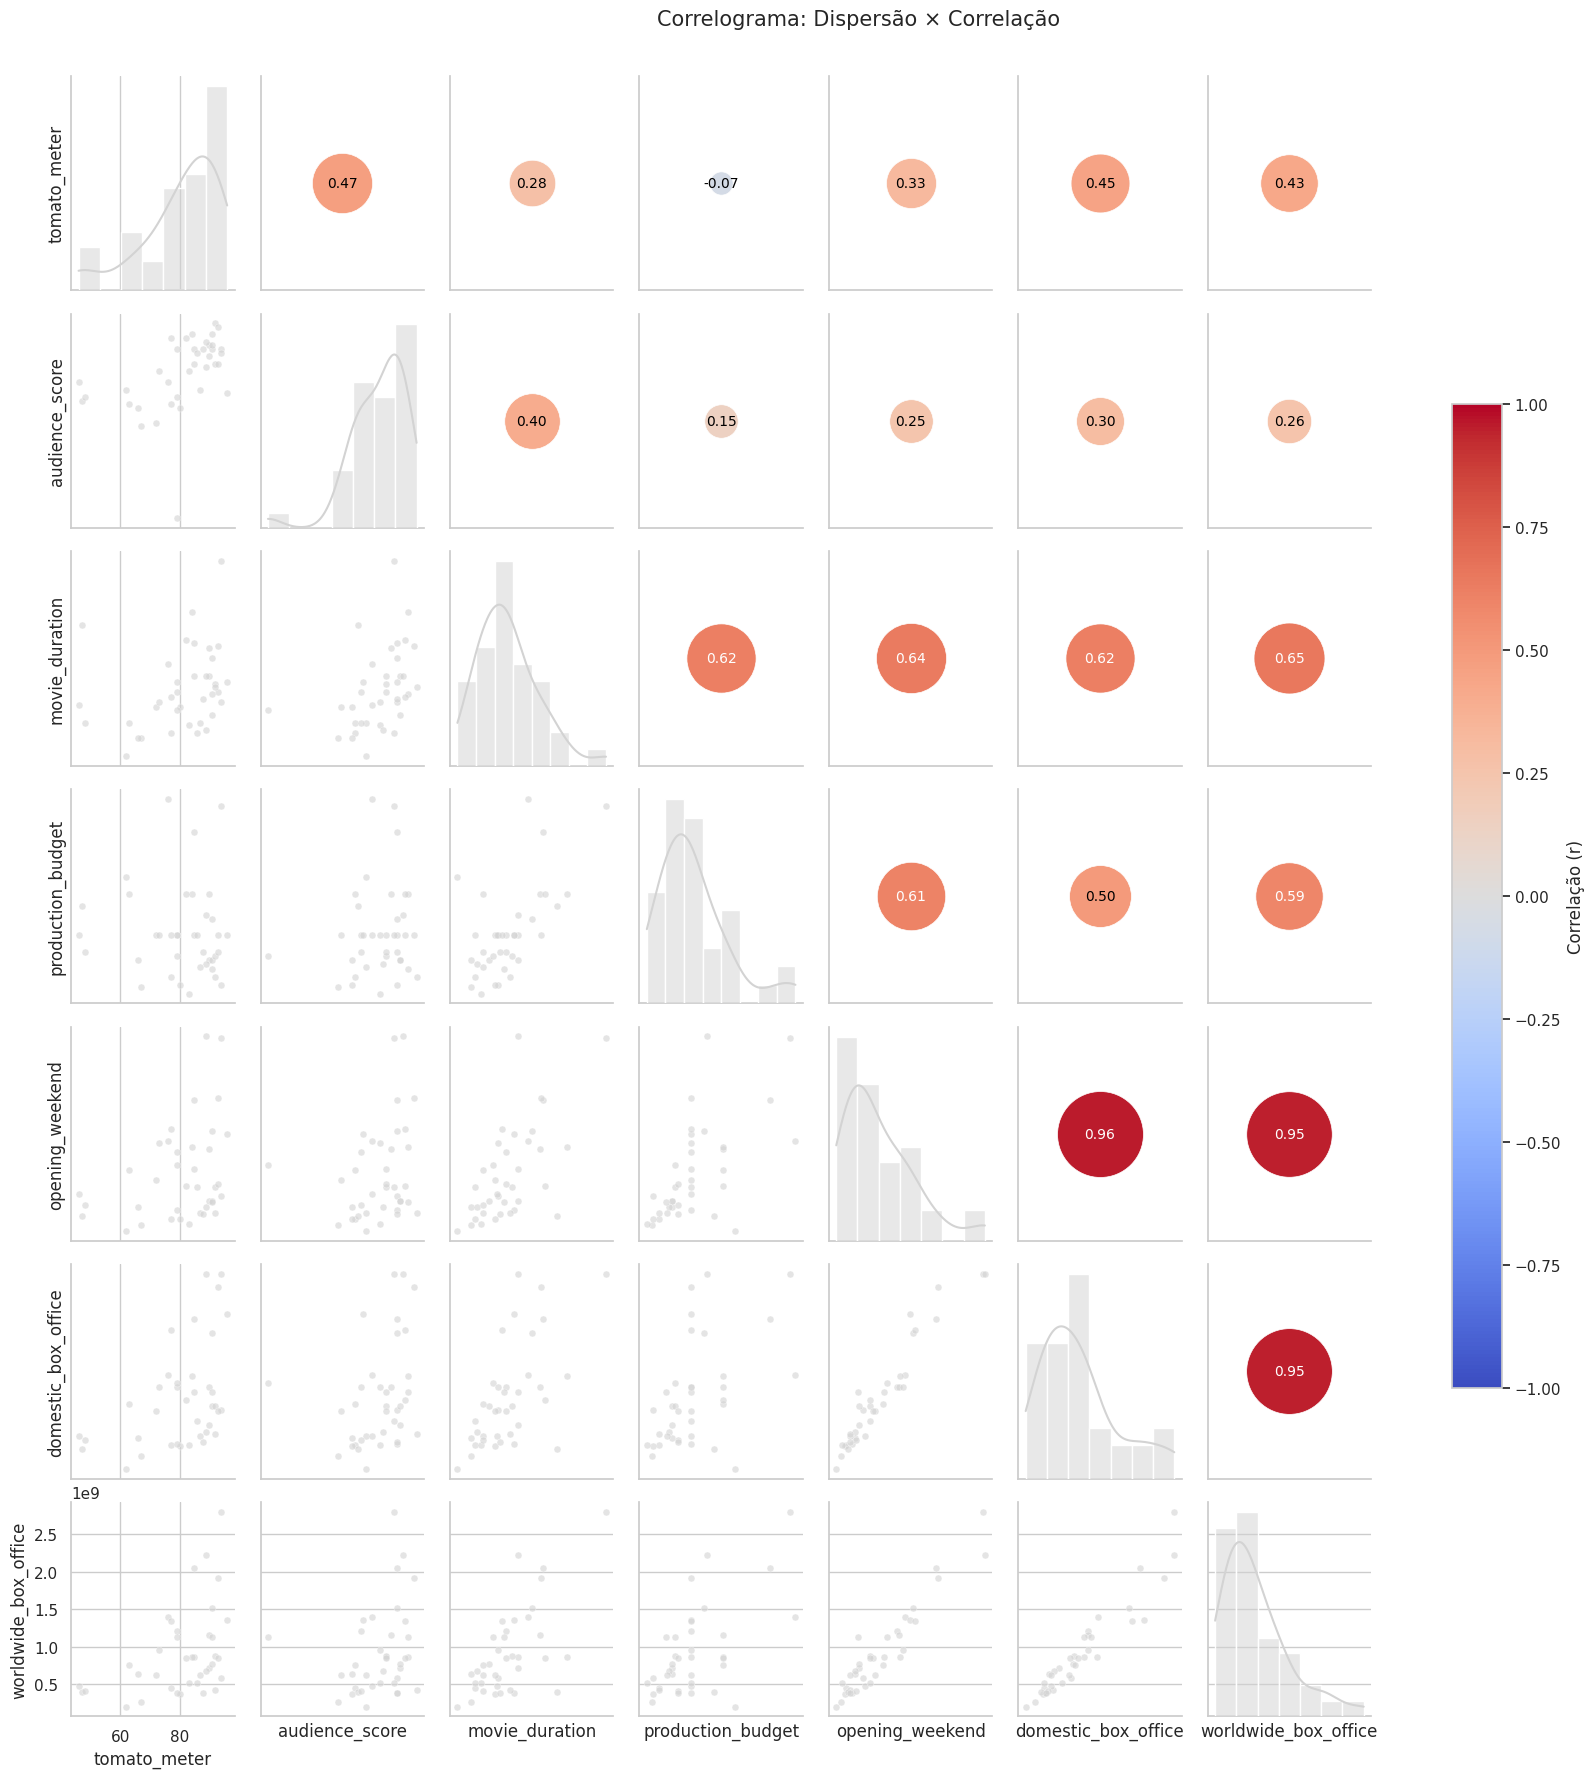

In [56]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = np.corrcoef(x, y)[0, 1]
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,          # tamanho proporcional à força da correlação
        c=[r], cmap='coolwarm', vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=10,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

g = sns.PairGrid(df[VARS_QUANT], diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.6, s=25)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

# barra de cor única, compartilhada (cada subplot superior tem seu próprio scatter)
sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação (r)")

g.fig.suptitle("Correlograma: Dispersão × Correlação", y=1.02, fontsize=15)


## Hands-on!

Agora é a vez de você realizar uma EDA com os seu conjunto de dados recebidos.

Para isso crie um novo notebook e vamos fazer **em sala** uma EDA seguindo a aula prática que acabamos de ter. Os tópicos desenvolvidos são referências.

Para esse exercício é de suma importância que vocês **elaborem perguntas** e **discutam** os resultados obtidos. Por exemplo, se houver dados faltantes, busque *entender* o porquê e *justifique* sua decisão.

Após o desenvolvimento da EDA em si, é necessário fazer uma síntese considerando:


1.   Principais conclusões em 3 a 5 pontos
2.   Declaração de Uso de IA (Ferramenta utilizada, Para o que foi aplicada e o que foi aceito/modificado/rejeitado e por quê)

O **entregável** será um notebook `ipynb`que trará todo o código, discussão, principais conclusões e declaração de uso de IA.




## Exportando o dataset tratado

Última etapa: salvar o dataset tratado em , que é o arquivo lido pelo app Streamlit ().

In [ ]:
# [IA] Claude Code – célula de exportação do dataset tratado para data/clean/dataset.csv
import os
import numpy as np
import pandas as pd

# Mesmo tratamento das Seções 4 e 6: só filmes (séries de TV não têm bilheteria),
# outliers mantidos, alvo binário e faixas usadas na avaliação de fairness
# Rodando de notebooks/ (local) a raiz do repo é "..". No Colab, usa o path do kagglehub
RAIZ = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
CAMINHO_RAW = os.path.join(path, "mcu.csv") if "path" in globals() else os.path.join(RAIZ, "data/raw/mcu.csv")
COLS_FINANCEIRAS = ["movie_duration", "production_budget", "opening_weekend", "domestic_box_office", "worldwide_box_office"]

df_export = pd.read_csv(CAMINHO_RAW).dropna(subset=COLS_FINANCEIRAS).reset_index(drop=True)
df_export[COLS_FINANCEIRAS] = df_export[COLS_FINANCEIRAS].astype("int64")
df_export["resultado_financeiro"] = np.where(
    df_export["worldwide_box_office"] > df_export["production_budget"], "Lucrativo", "Prejuízo"
)
df_export["worldwide_box_office_log"] = np.log1p(df_export["worldwide_box_office"])
df_export["ano_lancamento"] = pd.to_datetime(df_export["release_date"]).dt.year
df_export["decada"] = pd.cut(df_export["ano_lancamento"], bins=[2007, 2012, 2017, 2022, 2030],
                             labels=["2008-2012", "2013-2017", "2018-2022", "2023+"])
df_export["faixa_orcamento"] = pd.cut(df_export["production_budget"], bins=[0, 150e6, 200e6, 250e6, 1e9],
                                      labels=["<150M", "150-200M", "200-250M", "250M+"])

DESTINO = os.path.join(RAIZ, "data/clean/dataset.csv")
os.makedirs(os.path.dirname(DESTINO), exist_ok=True)
df_export.to_csv(DESTINO, index=False)
print(f"{df_export.shape[0]} filmes x {df_export.shape[1]} colunas exportados para {DESTINO}")